In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go   # pip install plotly (already in Colab)



In [2]:
# Processed dataset from Assignment 2
path = '../data/processed/menu_clean.csv' if os.path.exists('../data/processed/menu_clean.csv') else 'menu_clean.csv'
menu = pd.read_csv(path)
menu.head()


,restaurant,type,category,item,diet,ingredient,calories,protein,carbs,fat,...,price,data_status,cal_per_100g,protein_per_100g,sodium_per_100g,sugar_per_100g,price_per_100g,protein_per_dollar,sodium_per_cal,group
0,McDonald's,Fast Food,Burger,Big Mac,Non Vegetarian,Beef,580,25.0,45.0,34.0,...,7.79,ok,264.840183,11.415525,484.018265,2.283105,3.557078,3.209243,1.827586,Handheld
1,McDonald's,Fast Food,Burger,Quarter Pounder with Cheese,Non Vegetarian,Beef,520,30.0,42.0,26.0,...,7.89,ok,261.306533,15.075377,572.864322,4.020101,3.964824,3.802281,2.192308,Handheld
2,McDonald's,Fast Food,Burger,McDouble,Non Vegetarian,Beef,390,22.0,32.0,20.0,...,3.29,ok,261.744966,14.765101,617.449664,4.026846,2.208054,6.686930,2.358974,Handheld
3,McDonald's,Fast Food,Sandwich,McChicken,Non Vegetarian,Chicken,390,14.0,38.0,21.0,...,2.99,ok,229.411765,8.235294,329.411765,2.352941,1.758824,4.682274,1.435897,Handheld
4,McDonald's,Fast Food,Sandwich,McCrispy,Non Vegetarian,Chicken,470,26.0,46.0,20.0,...,5.79,ok,235.000000,13.000000,570.000000,4.500000,2.895000,4.490501,2.425532,Handheld


**Task 1**

In [3]:
# 1.1 Settings shared by the static and the interactive version (same data, colors, symbols, axes, density lines)
out_dir = '../visualizations'      # where the static and interactive versions are saved
os.makedirs(out_dir, exist_ok=True)

colors = {'Fast Food': '#d95f02', 'Fast Casual': '#1b9e77', 'Casual Dining': '#7570b3'}
rest_order = ["McDonald's", 'Taco Bell', "Wendy's", 'Chipotle', 'Panera', "Chili's", 'Cheesecake Factory']
rest_type = menu.drop_duplicates('restaurant').set_index('restaurant')['type'].to_dict()

# restaurants of the same type share a color, so each one also gets its own marker shape
symbols = {"McDonald's": 'circle', 'Taco Bell': 'square', "Wendy's": 'diamond',
           'Chipotle': 'circle', 'Panera': 'square',
           "Chili's": 'circle', 'Cheesecake Factory': 'square'}
mpl_marker = {'circle': 'o', 'square': 's', 'diamond': 'D'}

density_lines = [100, 200, 300, 400]      # calories per 100 g
x_max, y_max = 720, 2000                  # same axis ranges in both versions
print(menu.groupby('restaurant').size().loc[rest_order])


restaurant
McDonald's            14
Taco Bell             14
Wendy's               14
Chipotle              12
Panera                14
Chili's               15
Cheesecake Factory    15
dtype: int64


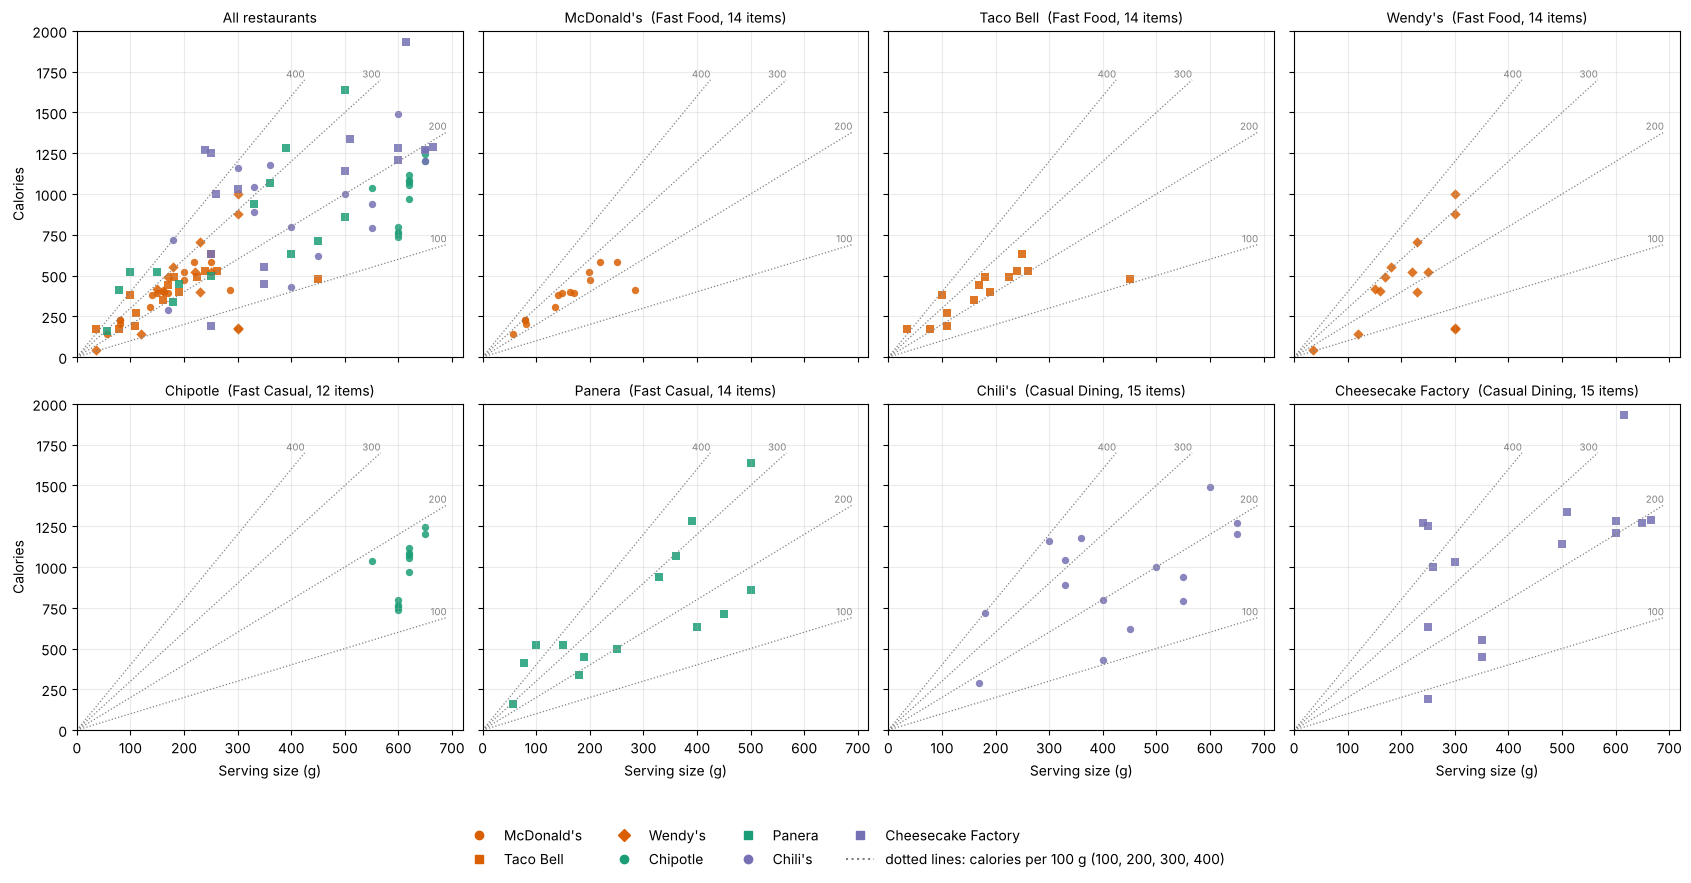

In [4]:
# 1.2 Static version: small multiples. One panel with all items, then one panel per restaurant, all on the same axes
fig, axes = plt.subplots(2, 4, figsize=(17, 8.6), sharex=True, sharey=True)
panels = [('All restaurants', menu)] + [(r, menu[menu['restaurant'] == r]) for r in rest_order]

for ax, (title, d) in zip(axes.flatten(), panels):
    for r in rest_order:
        dr = d[d['restaurant'] == r]
        ax.scatter(dr['serving_g'], dr['calories'], color=colors[rest_type[r]], marker=mpl_marker[symbols[r]],
                   s=28, alpha=0.85, linewidths=0)
    for k in density_lines:
        x_end = min(x_max - 30, (y_max - 300) * 100 / k)
        ax.plot([0, x_end], [0, x_end * k / 100], ':', color='gray', linewidth=0.9)
        ax.text(x_end, x_end * k / 100, str(k), fontsize=7, color='gray', ha='right', va='bottom')
    suffix = '' if title == 'All restaurants' else f'  ({rest_type[title]}, {len(d)} items)'
    ax.set_title(title + suffix, fontsize=10)
    ax.set_xlim(0, x_max); ax.set_ylim(0, y_max)
    ax.grid(alpha=0.25)

for ax in axes[1]:
    ax.set_xlabel('Serving size (g)')
for ax in axes[:, 0]:
    ax.set_ylabel('Calories')

handles = [plt.Line2D([], [], marker=mpl_marker[symbols[r]], ls='', color=colors[rest_type[r]], label=r) for r in rest_order]
handles.append(plt.Line2D([], [], ls=':', color='gray', label='dotted lines: calories per 100 g (100, 200, 300, 400)'))
fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.03))
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.savefig(out_dir + '/static.png', dpi=130, bbox_inches='tight')
plt.show()


In [5]:
# 1.3 Static version as a web page (the image is embedded, so the single file can be opened offline)
import base64
b64 = base64.b64encode(open(out_dir + '/static.png', 'rb').read()).decode()
intro = ("Each marker is one menu item. Position shows serving size (x) and calories (y); color shows the restaurant type "
         "and the shape tells restaurants of the same type apart. The dotted lines connect items with the same calories per 100 g "
         "(100, 200, 300 and 400): the higher a marker is above a line, the denser the item. "
         "The first panel shows all restaurants; the other panels show one restaurant each, on the same axes.")
html = f'''<!DOCTYPE html><html lang="en"><head><meta charset="utf-8"><title>Serving size vs calories (static)</title>
<style>body{{font-family:system-ui,sans-serif;margin:16px;color:#222}}h1{{font-size:18px}}p{{font-size:14px;max-width:1000px}}img{{max-width:100%}}</style></head>
<body><h1>Serving size vs calories, 98 menu items from 7 restaurants</h1><p>{intro}</p>
<img src="data:image/png;base64,{b64}" alt="Static small multiples"></body></html>'''
open(out_dir + '/static.html', 'w').write(html)


460259

In [6]:
# 1.4 Interactive version: one chart. Hide or show restaurants (legend click, or the dropdown) and hover for the item
fig_i = go.Figure()

# dotted density lines (always visible, not in the legend)
for k in density_lines:
    x_end = min(x_max - 30, (y_max - 300) * 100 / k)
    fig_i.add_trace(go.Scatter(x=[0, x_end], y=[0, x_end * k / 100], mode='lines+text', text=['', str(k)],
                               textposition='top left', textfont=dict(size=10, color='gray'),
                               line=dict(color='gray', dash='dot', width=1), hoverinfo='skip', showlegend=False))

# one trace per restaurant, legend grouped by restaurant type
for r in rest_order:
    d = menu[menu['restaurant'] == r]
    hover = ('<b>' + d['item'] + '</b><br>' + r + ' (' + rest_type[r] + ')<br>' +
             d['serving_g'].astype(int).astype(str) + ' g, ' + d['calories'].astype(int).astype(str) + ' calories<br>' +
             d['cal_per_100g'].round(0).astype(int).astype(str) + ' calories per 100 g')
    fig_i.add_trace(go.Scatter(x=d['serving_g'], y=d['calories'], mode='markers', name=r,
                               legendgroup=rest_type[r], legendgrouptitle_text=rest_type[r],
                               text=hover, hoverinfo='text',
                               marker=dict(color=colors[rest_type[r]], symbol=symbols[r], size=9, opacity=0.85)))

# dropdown: quick subsets (the legend can combine any restaurants)
n_lines = len(density_lines)
def visibility(selected):
    return [True] * n_lines + [True if r in selected else 'legendonly' for r in rest_order]

types = ['Fast Food', 'Fast Casual', 'Casual Dining']
buttons = [dict(label='All restaurants', method='update', args=[{'visible': visibility(rest_order)}])]
buttons += [dict(label=t + ' only', method='update', args=[{'visible': visibility([r for r in rest_order if rest_type[r] == t])}]) for t in types]
buttons += [dict(label=r + ' only', method='update', args=[{'visible': visibility([r])}]) for r in rest_order]

fig_i.update_layout(
    template='plotly_white', width=1000, height=640, margin=dict(t=110, b=90),
    title=dict(text='Serving size vs calories, 98 menu items', x=0.0),
    xaxis=dict(title='Serving size (g)', range=[0, x_max]),
    yaxis=dict(title='Calories', range=[0, y_max]),
    dragmode='pan',                      # drag to pan, scroll to zoom, double-click to reset
    legend=dict(title_text='Restaurants (click to hide or show, double-click to show only one)'),
    updatemenus=[dict(buttons=buttons, direction='down', x=0.0, y=1.08, xanchor='left', showactive=True)],
    annotations=[dict(xref='paper', yref='paper', x=0, y=-0.17, xanchor='left', showarrow=False, font=dict(size=11),
                      text='Each marker is one menu item. Color = restaurant type, shape = restaurant. Dotted lines = calories per 100 g (100, 200, 300, 400). Scroll to zoom, drag to pan, double-click to reset.')])
fig_i.show(config={'displayModeBar': False, 'scrollZoom': True})


In [7]:
# 1.5 Save the interactive version as a web page (self-contained, works offline in a browser)
fig_i.write_html(out_dir + '/interactive.html', include_plotlyjs=True, config={'displayModeBar': False, 'scrollZoom': True})
os.listdir(out_dir)


['interactive.html',
 'screenshot_interactive_filtered.png',
 'static.html',
 'static.png']